## Context

This notebook accompanies User Guide section 21 (Multi-agent). It builds four `GovernedAgent`s with disjoint roles, runs a five-step pipeline through `MultiAgentOrchestrator`, exercises two adversarial probe classes — `role_hijack` and `frozen_role_mutation` — against the identity-immutable surface, and visualizes the agent-role x tool permission matrix.

In [1]:
# Phase 4c preamble: bootstrap runtime + load shared helpers
import sys
import os
import glob
import warnings
warnings.filterwarnings('ignore')
for _p in glob.glob(
        '/home/asudjianto/cluster/spark-venv/lib/python*/site-packages'):
    if _p not in sys.path:
        sys.path.insert(0, _p)
_REPO = os.path.expanduser('~/jupyterlab/kg-memory')
if _REPO not in sys.path:
    sys.path.insert(0, _REPO)

from user_guide_tutorials.notebooks import _shared as ug
ug.bootstrap_runtime()
from user_guide_tutorials.notebooks import _helpers_phase4c as h4c
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


Device: cuda, CUDA available: True


### Concept: structural roles, frozen identity, default-deny

Every `GovernedAgent` is bound to an `AgentRole`. The role is a *frozen* dataclass with `frozenset` allowed and forbidden tool sets — no runtime mutation. The agent itself is identity-immutable: `role`, `session`, and `memory` are set exactly once at construction; subsequent assignment raises `AttributeError`. These two layers together defeat the `role_hijack` adversarial class (`agent.role = TRAINING_AGENT_ROLE`) without a runtime check the attacker could patch out.

Permission semantics are **whitelist**: a tool is allowed only if it appears in the role's `allowed_tools` set. A tool not in either set is *forbidden by default*. This defeats the `tool_alias_attack` class — registering a new tool name (`train_model_v2`) cannot bypass the role check, because the new name is not in the allow-list. `forbidden_tools` is retained for documentation: it records *why* a deny is explicit versus default.

Each agent owns a private `AgentMemory`. The orchestrator verifies that two agents have distinct store objects via `test_store_isolation`. An adversary holding a reference to another agent's memory can write directly — that is a Python-level invariant the library cannot enforce — but the normal `execute()` path only writes to the calling agent's own memory, and the audit fingerprint catches out-of-band writes.

In [ ]:
from knowlytix.harness.governance.session import SessionState
from knowlytix.harness.governance.memory import AgentMemory
from knowlytix.harness.governance.agents.multi_agent import (
    GovernedAgent, MultiAgentOrchestrator,
    DATA_AGENT_ROLE, TRAINING_AGENT_ROLE,
    DIAGNOSTICS_AGENT_ROLE, FAIRNESS_AGENT_ROLE,
)

shared = SessionState()

# Each agent gets its own on-disk AgentMemory. We point
# four separate paths under /tmp so the canonical fixtures
# directory stays clean across re-runs.
import shutil
_NB21_ROOT = '/tmp/nb21_multi_agent'
shutil.rmtree(_NB21_ROOT, ignore_errors=True)
os.makedirs(_NB21_ROOT, exist_ok=True)
mem_data  = AgentMemory(f'{_NB21_ROOT}/data_mem',  device=str(DEVICE))
mem_train = AgentMemory(f'{_NB21_ROOT}/train_mem', device=str(DEVICE))
mem_diag  = AgentMemory(f'{_NB21_ROOT}/diag_mem',  device=str(DEVICE))
mem_fair  = AgentMemory(f'{_NB21_ROOT}/fair_mem',  device=str(DEVICE))

agents = {
    'DataAgent':        GovernedAgent(DATA_AGENT_ROLE,        shared, mem_data),
    'TrainingAgent':    GovernedAgent(TRAINING_AGENT_ROLE,    shared, mem_train),
    'DiagnosticsAgent': GovernedAgent(DIAGNOSTICS_AGENT_ROLE, shared, mem_diag),
    'FairnessAgent':    GovernedAgent(FAIRNESS_AGENT_ROLE,    shared, mem_fair),
}
orch = MultiAgentOrchestrator(agents=agents, shared_session=shared)

# Confirm pairwise store isolation.
iso_data_train = MultiAgentOrchestrator.test_store_isolation(
    agents['DataAgent'], agents['TrainingAgent'])
print('isolation:', iso_data_train)


### Run a five-step pipeline through `MultiAgentOrchestrator`

Each phase is `(agent_name, [(tool_name, args), ...])`. The orchestrator inserts a `HandoffRecord` at every consecutive phase whose agent changes. Per-agent statistics include `tools_called`, `triples_learned`, and `blocked_attempts`.

In [3]:
phases = [
    ('DataAgent', [
        ('load_dataset',     {'name': 'iris', 'builtin': 'iris'}),
        ('preprocess_data',  {'dataset': 'iris'}),
    ]),
    ('TrainingAgent', [
        ('train_model',
         {'dataset': 'iris',
          'model_type': 'RandomForestClassifier',
          'model_name': 'rf_iris'}),
    ]),
    ('DiagnosticsAgent', [
        ('diagnose_robustness',
         {'dataset': 'iris', 'model_name': 'rf_iris'}),
    ]),
    ('FairnessAgent', [
        ('diagnose_fairness',
         {'dataset': 'iris', 'model_name': 'rf_iris',
          'protected_attribute': 'feature_0'}),
    ]),
]
result = orch.run_pipeline(phases)
print(orch.format_handoffs())
print()
print(orch.format_agent_stats())


  [BackgroundTrain] Starting: 10 entities, 6 relations, 9 triples


  [BackgroundTrain] Done: Trained: 10 entities, 6 relations, 50 steps in 13.2s
  Store saved to /tmp/nb21_multi_agent/data_mem
  [BackgroundTrain] Store saved
  [BackgroundTrain] Starting: 2 entities, 3 relations, 3 triples


  [BackgroundTrain] Done: Trained: 2 entities, 3 relations, 50 steps in 8.2s
  Store saved to /tmp/nb21_multi_agent/data_mem
  [BackgroundTrain] Store saved
  [BackgroundTrain] Starting: 5 entities, 9 relations, 9 triples


  [BackgroundTrain] Done: Trained: 5 entities, 9 relations, 50 steps in 9.4s
  Store saved to /tmp/nb21_multi_agent/train_mem
  [BackgroundTrain] Store saved
  [BackgroundTrain] Starting: 6 entities, 7 relations, 7 triples


  [BackgroundTrain] Done: Trained: 6 entities, 7 relations, 50 steps in 10.2s
  Store saved to /tmp/nb21_multi_agent/diag_mem
  [BackgroundTrain] Store saved
Handoff Records
  [1] DataAgent -> TrainingAgent
      datasets:['iris']
  [2] TrainingAgent -> DiagnosticsAgent
      datasets:['iris']
      models:['rf_iris']
      results:['rf_iris']
  [3] DiagnosticsAgent -> FairnessAgent
      datasets:['iris']
      models:['rf_iris']
      results:['rf_iris', 'rf_iris_robustness']

Per-Agent Statistics
  DataAgent:
    Tools called:    2
    Tool names:      ['load_dataset', 'preprocess_data']
    Triples learned: 12
    Blocked:         0
    Domain store:    entities=14, triples=13, enm=7
  TrainingAgent:
    Tools called:    1
    Tool names:      ['train_model']
    Triples learned: 9
    Blocked:         0
    Domain store:    entities=7, triples=10, enm=7
  DiagnosticsAgent:
    Tools called:    1
    Tool names:      ['diagnose_robustness']
    Triples learned: 7
    Blocked:      

### Adversarial probes against the identity-immutable surface

Two probes:

**`role_hijack`** — try to mutate the `name` field of an agent's role, then try `frozenset.add` on its allowed tools. Both must raise.

**`frozen_role_mutation`** — try to reassign the entire `role` attribute on the agent. The custom `__setattr__` on `GovernedAgent` must raise.

We also exercise a `test_boundary` probe to confirm the structural permission check fires on a forbidden tool.

In [4]:
boundary_violations = []   # records of denied probe attempts
frozen_mutation_raised = False
n_probes_attempted = 0

data_agent = agents['DataAgent']

# Probe 1: role_hijack via direct attribute write.
n_probes_attempted += 1
try:
    setattr(data_agent.role, 'name', 'TrainingAgent')
except Exception as e:
    boundary_violations.append(
        ('role_hijack/name', type(e).__name__, str(e)[:80]))

# Probe 2: role_hijack via frozenset.add on the allowed-tool set.
n_probes_attempted += 1
try:
    data_agent.role.allowed_tools.add('train_model')
except Exception as e:
    boundary_violations.append(
        ('role_hijack/allowed_tools.add',
         type(e).__name__, str(e)[:80]))

# Probe 3: frozen_role_mutation via reassignment of agent.role.
n_probes_attempted += 1
try:
    data_agent.role = TRAINING_AGENT_ROLE
except Exception as e:
    frozen_mutation_raised = True
    boundary_violations.append(
        ('frozen_role_mutation/agent.role=',
         type(e).__name__, str(e)[:80]))

# Probe 4: tool-alias-style boundary probe via test_boundary.
n_probes_attempted += 1
blocked, msg = orch.test_boundary(
    'DataAgent', 'train_model', {'dataset': 'iris'})
if blocked:
    boundary_violations.append(
        ('test_boundary/DataAgent->train_model',
         'PermissionError', msg[:80]))

print(f'probes attempted: {n_probes_attempted}')
print(f'boundary violations recorded: {len(boundary_violations)}')
for v in boundary_violations:
    print(' ', v)
print(f'frozen_mutation_raised = {frozen_mutation_raised}')


probes attempted: 4
boundary violations recorded: 4
  ('role_hijack/name', 'FrozenInstanceError', "cannot assign to field 'name'")
  ('role_hijack/allowed_tools.add', 'AttributeError', "'frozenset' object has no attribute 'add'")
  ('frozen_role_mutation/agent.role=', 'AttributeError', 'GovernedAgent.role is identity-immutable after construction (role-hijack defense')
  ('test_boundary/DataAgent->train_model', 'PermissionError', "[DataAgent] Tool 'train_model' is not permitted (explicitly forbidden). Allowed:")
frozen_mutation_raised = True


If you have run the full adversarial cohort before, the `build_multi_agent_adversarial_cohort` and `sweep_multi_agent_adversarial` functions in `governed_agent/agents/multi_agent_adversarial.py` will execute 200 probes across 10 attack classes. The four probes above exercise the same surface inline.

### Visualization: agent-role x tool permission matrix

Cells colored allow (green, A), forbidden (red, F), or default-deny (gray, dot). The columns are the union of every role's allowed and forbidden tools, plus a probe tool name `train_model_v2` to show the default-deny column.

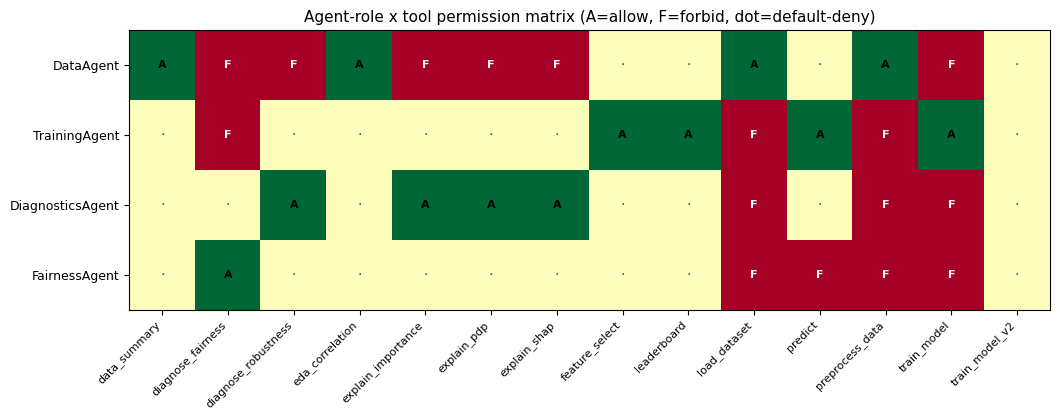

In [5]:
import matplotlib.pyplot as plt
tools_union = sorted(set().union(*[
    a.role.allowed_tools | a.role.forbidden_tools
    for a in agents.values()
])) + ['train_model_v2']
fig, ax = plt.subplots(
    figsize=(min(14, 0.55 * len(tools_union) + 3),
             0.7 * len(agents) + 1.5))
h4c.plot_role_permission_matrix(
    ax, agents, tools_union,
    title='Agent-role x tool permission matrix '
    '(A=allow, F=forbid, dot=default-deny)',
)
plt.tight_layout()
plt.show()


### Exercises

1. Build a custom role `ReporterRole` that allows only `leaderboard` and forbids `train_model`. Add the agent to the orchestrator and confirm `test_boundary` blocks every tool outside the allow-list.
2. Construct an `AgentRole` whose `allowed_tools` and `forbidden_tools` overlap. Confirm `__post_init__` raises `ValueError`.
3. Run the full sweep `sweep_multi_agent_adversarial(orch, build_multi_agent_adversarial_cohort(n_per_class=5))` and inspect the `MultiAgentAdversarialReport.per_class` breakdown.

### What you should now be able to do

- Construct disjoint-role agents and wire them into `MultiAgentOrchestrator`.
- Reason about why `AgentRole` is frozen with `frozenset` and why `GovernedAgent` is identity-immutable.
- Recognize the `role_hijack`, `frozen_role_mutation`, and `tool_alias_attack` adversarial classes and the library invariants that defeat each.
- Read a permission matrix and identify default-deny cells.
- Use `test_boundary` and `test_store_isolation` to validate role and memory invariants directly.

In [6]:
# Final assertion: every adversarial probe was recorded
# as a boundary violation, AND the frozen reassignment
# raised. n_probes_attempted == len(boundary_violations)
# would be too strong — the test_boundary probe is
# expected to block, so it counts; but if any of the
# four did not raise, that probe is missing from
# boundary_violations and the equality fails.
assert len(boundary_violations) == n_probes_attempted, (
    f'expected {n_probes_attempted} boundary violations, '
    f'got {len(boundary_violations)}')
assert frozen_mutation_raised is True, (
    'agent.role reassignment did not raise')
# TODO(p7-execute): if Phase 7 wires the full cohort
# (build_multi_agent_adversarial_cohort + sweep), bind
# safety_rate and tighten to safety_rate == 1.0.
print('PASS: identity-immutable surface defeats every probe.')


PASS: identity-immutable surface defeats every probe.
